# Esperienza 8 — Calibrazione del sensore di pressione con la legge di Boyle

### Scopo
Si vuole calibrare il sensore di pressione **CI-6534** (Low Pressure Sensor) misurando come varia la pressione di una quantità fissa di aria, a temperatura ambiente costante, quando se ne riduce il volume con una siringa. L'andamento osservato si confronta con quello previsto dalla legge di Boyle: la pendenza della retta di fit fornisce il coefficiente di calibrazione del sensore, da usare nelle esperienze successive.

### Apparato
- bottiglia di vetro di volume $V_b = (1111 \pm 5)\ \mathrm{cm^3}$ (tappo incluso), collegata al sensore di pressione;
- siringa a tenuta collegata alla bottiglia, usata per comprimere il gas a passi di $\Delta V \approx 10\ \mathrm{ml}$;
- distanziatori di legno per tenere ferma la siringa durante ogni stallo;
- sensore CI-6534, acquisito con DataStudio.

Il gas compresso è **tutta l'aria del sistema bottiglia + siringa**, non solo quella della siringa: per questo il volume di riferimento $V_0$ comprende anche la bottiglia (vedi più avanti).

### Modello (dalla scheda)
Per un gas perfetto a temperatura costante vale
$$pV = nRT = \text{costante}. \tag{2}$$
Partendo dalla pressione atmosferica $p_0$ e dal volume $V_0$, per piccole variazioni di volume si sviluppa al primo ordine:
$$p = p_0 + \frac{dp}{dV}(V - V_0) = p_0 - \frac{nRT}{V_0^2}(V - V_0). \tag{3}$$
Definendo $\Delta p = p - p_0$ e $\Delta V = V - V_0$ si ottiene la relazione usata nel fit:
$$\boxed{\ \frac{\Delta p}{p_0} = -\,\frac{\Delta V}{V_0}\ } \tag{4}$$
Con il grafico $\Delta p/p_0$ in funzione di $\Delta V/V_0$ ci si aspetta quindi una retta con **pendenza $-1$** e **intercetta $0$**. Se la pendenza misurata è diversa da $-1$, il sensore ha un errore di guadagno, e il suo valore è proprio il coefficiente di calibrazione.

> L'eq. (4) è un'approssimazione al primo ordine, valida per $|\Delta V| \ll V_0$. Qui si arriva al massimo a $|\Delta V|/V_0 \approx 50/1165 \approx 4\%$.

### Preparazione dell'ambiente
Le prime celle importano i moduli e fissano la cartella di lavoro.


In [8]:
import sys
import os

Nel notebook la variabile `__file__` non esiste: la cartella di lavoro è quella in cui si trova il notebook (`8/`). Tutti i percorsi dei dati (`8/8-1.txt`, ...) e il modulo `info.py` con le caratteristiche degli strumenti sono invece relativi alla cartella `PP2`. Se `info.py` non si trova nella cartella corrente si sale di un livello, e la cartella si aggiunge a `sys.path` per poter fare `import info`.


In [9]:
if not os.path.exists("info.py"):
    os.chdir("..")
sys.path.append(os.getcwd())

Librerie usate:
- `numpy` per i calcoli;
- `sliding_window_view` per calcolare in modo vettoriale la deviazione standard su una finestra mobile, usata per riconoscere gli stalli;
- `info`, che contiene risoluzione, accuracy e incertezza di tipo B $\sigma_B$ di ogni strumento della postazione.

In `info.py` l'incertezza di tipo B di ogni strumento è
$$\sigma_B = \sqrt{\left(\frac{\text{risoluzione}}{\sqrt{12}}\right)^2 + \text{accuracy}^2}.$$
- La **risoluzione** entra divisa per $\sqrt{12}$: l'errore di lettura è distribuito uniformemente su un intervallo largo quanto la risoluzione.
- L'**accuracy** si tiene su ogni lettura. Non si può trattare come un offset da eliminare, perché la curva di risposta del sensore non è nota: non si sa quanto valga punto per punto.


In [10]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import info

### Lettura dei file
DataStudio esporta i dati con la **virgola** come separatore decimale (`12,34`), che `numpy` non riconosce come numero. La funzione `comma_to_float` sostituisce la virgola con il punto prima della conversione. I file sono in codifica `latin1`, quindi se `loadtxt` passa dei `bytes` vengono prima decodificati.


In [11]:
def comma_to_float(x):
    if isinstance(x, bytes):
        x = x.decode('latin1')
    return float(x.replace(',', '.'))

### Riconoscimento automatico degli stalli: parametri
Durante l'acquisizione la siringa viene spinta di circa 10 ml alla volta e poi bloccata con i distanziatori. Il segnale di pressione è quindi una **scala**: tratti piatti (gli *stalli*, a volume costante) separati da salti brevi durante le compressioni. Per ogni stallo serve la pressione di equilibrio, quindi bisogna isolare automaticamente i tratti piatti ed escludere i transitori.

Il criterio è la **deviazione standard su una finestra mobile**. In uno stallo la pressione è costante e la dispersione è solo il rumore di quantizzazione del sensore, dell'ordine di un LSB. Durante una compressione invece la pressione cambia e la dispersione cresce molto.

| Parametro | Valore | Significato |
|---|---|---|
| `LSB` | risoluzione del CI-6534 | passo minimo del sensore, usato come unità di misura delle soglie |
| `window_s` | 3 s | ampiezza della finestra mobile su cui si calcola la std |
| `soglia` | $1.1\cdot$LSB | sotto questa std la finestra è considerata "ferma" |
| `min_dur_s` | 5 s | durata minima di uno stallo: i tratti più brevi sono transitori o assestamenti, non equilibri |
| `max_gap_s` | 3 s | se due zone ferme sono separate da un buco più breve di così... |
| `tol_merge` | $7\cdot$LSB | ...e i loro livelli differiscono meno di così, sono lo stesso stallo interrotto da un disturbo, e si uniscono |

Questi parametri servono solo a **selezionare i dati**: non entrano nel calcolo delle incertezze.


In [12]:
LSB        = info.risoluzione_pressione_CI6534  # risoluzione del sensore [kPa]
window_s   = 3.0        # finestra mobile [s]
soglia     = 1.1 * LSB  # soglia sulla std [kPa]
min_dur_s  = 5.0        # durata minima di uno stallo [s]
max_gap_s  = 3.0        # buco massimo tra due zone da unire [s]
tol_merge  = 7 * LSB    # differenza massima di livello per unire [kPa]

### Riconoscimento automatico degli stalli: algoritmo
La funzione `trova_stalli(t, P)` restituisce la lista degli intervalli di indici `(inizio, fine)` di ogni stallo:

1. **Finestra in campioni.** Dal passo temporale tipico `dt` (mediana di `diff(t)`) si ricava quanti campioni ci sono in `window_s` secondi.
2. **Std mobile.** `sliding_window_view` costruisce tutte le finestre consecutive e su ciascuna si calcola la deviazione standard campionaria (`ddof=1`). Il valore viene assegnato al punto centrale della finestra (spostamento `half`).
3. **Maschera "fermo".** Un punto è "fermo" se la std della sua finestra è sotto `soglia`.
4. **Zone contigue.** Con `diff` della maschera si trovano gli indici in cui la maschera passa da 0 a 1 (inizio zona) e da 1 a 0 (fine zona).
5. **Unione.** Una zona che segue la precedente a meno di `max_gap_s` secondi, con mediana della pressione entro `tol_merge`, viene unita alla precedente. Si usa la mediana e non la media perché è meno sensibile a eventuali picchi ai bordi.
6. **Filtro sulla durata.** Si tengono solo le zone lunghe almeno `min_dur_s`.

Il risultato va sempre controllato a occhio nel grafico di ogni prova: gli stalli trovati sono evidenziati a colori sopra i dati grezzi.


In [13]:
def trova_stalli(t, P):
    dt = np.median(np.diff(t))
    w = int(round(window_s / dt))
    half = w // 2

    stds = np.std(sliding_window_view(P, w), axis=1, ddof=1)

    is_st = np.zeros(len(P), dtype=bool)
    is_st[half:half + len(stds)] = stds < soglia

    d = np.diff(np.r_[0, is_st.astype(int), 0])
    starts, ends = np.flatnonzero(d == 1), np.flatnonzero(d == -1)

    zone = []
    for s, e in zip(starts, ends):
        if zone:
            ps, pe = zone[-1]
            vicine = (t[s] - t[pe - 1]) <= max_gap_s
            simili = abs(np.median(P[s:e]) - np.median(P[ps:pe])) < tol_merge
            if vicine and simili:
                zone[-1][1] = e
                continue
        zone.append([s, e])

    return [(s, e) for s, e in zone if t[e - 1] - t[s] >= min_dur_s]

### Costanti dell'esperimento
- `V_diff = 10 ml`: compressione tra uno stallo e il successivo, impostata con la siringa e i distanziatori.
- **Volume di riferimento $V_0$.** Il gas compresso è tutta l'aria contenuta nella bottiglia e nella siringa, quindi
$$V_0 = V_b + V_s = 1111\ \mathrm{ml} + 54\ \mathrm{ml} = 1165\ \mathrm{ml},$$
  dove $V_b = (1111 \pm 5)\ \mathrm{ml}$ è il volume della bottiglia dato dalla scheda (tappo incluso) e $V_s = 54\ \mathrm{ml}$ è il volume iniziale letto sulla siringa. Usare solo $V_s$ sarebbe sbagliato: con $V_0 = 54$ ml una compressione di 10 ml darebbe $\Delta p \approx p_0 \cdot 10/54 \approx 19$ kPa per stallo, mentre si misura circa 1 kPa. La pendenza verrebbe sottostimata di un fattore $V_s/V_0 \approx 0.05$.
- `sigma_V_b = 5 ml`: incertezza sul volume della bottiglia. Serve più avanti per l'incertezza sistematica sulla pendenza.
- `p_0 = 100.97 kPa`: pressione atmosferica letta sul barometro dell'aula, come richiesto dal punto 7 della scheda.

Le liste `m`, `sigma_m`, `q`, `sigma_q` raccolgono pendenza e intercetta di ogni ripetizione, per confrontarle alla fine.


In [14]:
V_diff = 10      # ml, compressione tra uno stallo e il successivo
V_b = 1111       # ml, volume della bottiglia di vetro (tappo incluso)
sigma_V_b = 5    # ml, incertezza sul volume della bottiglia
V_s = 54         # ml, volume iniziale della siringa
V_0 = V_b + V_s  # ml, volume totale del gas (bottiglia + siringa)
p_0 = 100.97     # kPa, pressione atmosferica (barometro dell'aula)

m, sigma_m = [], []
q, sigma_q = [], []

### Analisi di ogni ripetizione
Per ciascuna delle 4 prove (`8-1.txt` ... `8-4.txt`) la cella esegue questi passi.

#### 1. Pressione di ogni stallo e incertezza di tipo A
In ogni stallo la pressione è la **media** dei campioni del tratto piatto. Il punto che entra nel fit è proprio questa media, quindi la sua incertezza statistica è la deviazione standard **della media**:
$$\sigma_{A,j} = \frac{s_j}{\sqrt{n_j}}, \qquad s_j = \sqrt{\frac{1}{n_j - 1}\sum_k \left(P_k - \bar P_j\right)^2}.$$
Qui va divisa per $\sqrt{n}$ perché ogni punto del fit è una media di molte letture, non una lettura singola.

#### 2. Incertezza totale su ogni punto
$$\sigma_{p,j} = \sqrt{\sigma_{A,j}^2 + \sigma_B^2}, \qquad \sigma_B = \sqrt{\left(\frac{\text{ris}}{\sqrt{12}}\right)^2 + \text{acc}^2}$$
con $\sigma_B$ = `info.sigma_b_pressione_CI6534`. L'incertezza di tipo B **non si riduce mediando**: la risoluzione e soprattutto l'accuracy riguardano ogni lettura del sensore, e fare la media su più campioni dello stesso stallo non le elimina. Siccome $\sigma_A$ è molto piccola (stalli lunghi, rumore di un LSB), $\sigma_p$ è dominata dall'accuracy.

#### 3. Calcolo di $\Delta p$ e $\Delta V$
- Il CI-6534 misura la pressione **relativa all'ambiente**, quindi il valore letto è già $\Delta p = p - p_0$. Infatti il primo stallo, prima di qualsiasi compressione, dà $\Delta p \approx 0$.
- Il primo stallo corrisponde a $V = V_0$; ogni stallo successivo ha 10 ml in meno, quindi $\Delta V_j = -j \cdot V_\text{diff}$ (compressioni: $\Delta V < 0$, $\Delta p > 0$).

#### 4. Fit lineare con l'eq. (4)
$$x = \frac{\Delta V}{V_0}, \qquad y = \frac{\Delta p}{p_0}, \qquad \sigma_y = \frac{\sigma_p}{p_0}.$$
- $p_0$ e $V_0$ sono costanti in tutta la prova, quindi l'incertezza su $y$ è quella su $\Delta p$ divisa per $p_0$.
- Le $x$ si considerano senza errore: i passi da 10 ml sono fissati dai distanziatori. L'incertezza su $V_0$ è comune a tutti i punti e si tratta a parte, come sistematico sulla pendenza.
- `np.polyfit(..., w=1/sigma_y, cov='unscaled')` esegue un fit pesato ai minimi quadrati con pesi $1/\sigma_y$. Con `cov='unscaled'` la matrice di covarianza dipende solo dalle $\sigma_y$ assegnate, senza riscalarla per $\chi^2/\text{gdl}$: le incertezze su $m$ e $q$ vengono dalle incertezze sperimentali, non dalla dispersione dei residui.
- Il **$\chi^2$** con $\text{gdl} = N - 2$ (due parametri) controlla se le incertezze sono coerenti con la dispersione dei punti. Con $\sigma_p$ dominata dall'accuracy ci si aspetta $\chi^2/\text{gdl} \ll 1$: l'accuracy è grande rispetto al rumore, ma va mantenuta per il motivo spiegato sopra.

#### 5. Grafici
Per ogni prova si producono:
- il segnale di pressione nel tempo, con gli stalli selezionati evidenziati, per controllare la selezione automatica;
- il grafico $\Delta p/p_0$ in funzione di $\Delta V/V_0$ con la retta di fit.

**Come leggere il risultato:** l'intercetta $q$ deve essere compatibile con 0, perché a $\Delta V = 0$ il sensore deve leggere $\Delta p = 0$. La pendenza $m$ si confronta con $-1$.



Test 1
  Stallo 1:    1.50–  22.06 s  P = -0.0262 kPa | sigma_A = 0.00009 kPa
  Stallo 2:   39.36–  60.68 s  P = 0.9733 kPa | sigma_A = 0.00023 kPa
  Stallo 3:   72.04–  97.26 s  P = 1.9413 kPa | sigma_A = 0.00037 kPa
  Stallo 4:  109.70– 128.62 s  P = 2.9318 kPa | sigma_A = 0.00032 kPa
  Stallo 5:  144.10– 161.70 s  P = 3.9413 kPa | sigma_A = 0.00054 kPa
  Stallo 6:  173.08– 191.70 s  P = 4.9468 kPa | sigma_A = 0.00040 kPa


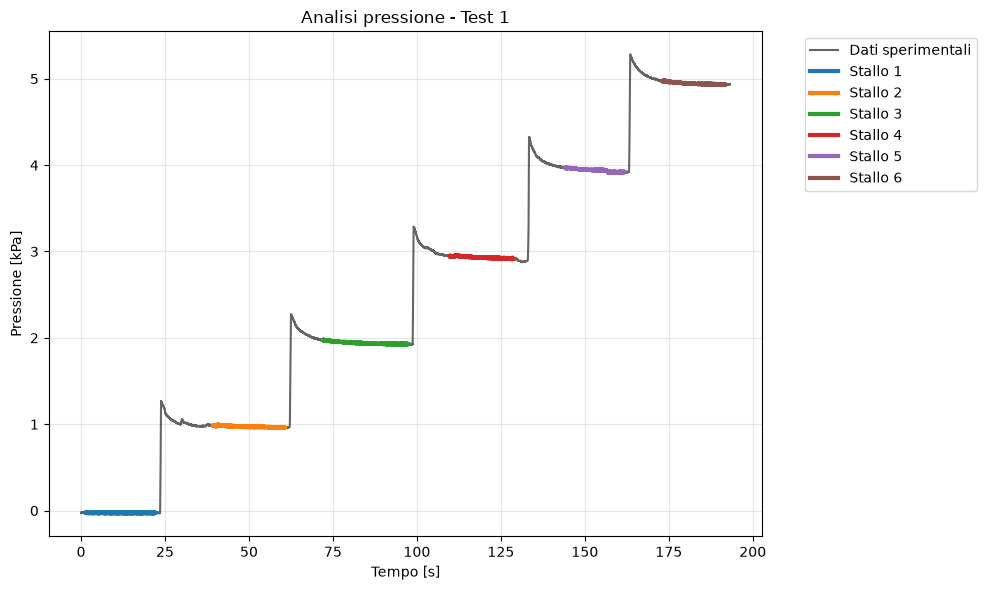


  delta p [kPa] | sigma [kPa] | delta V [ml]
    -0.0262     | 0.10201     |    0.0
     0.9733     | 0.10201     |  -10.0
     1.9413     | 0.10201     |  -20.0
     2.9318     | 0.10201     |  -30.0
     3.9413     | 0.10201     |  -40.0
     4.9468     | 0.10201     |  -50.0

  m = -1.1459 ± 0.0281  (atteso -1)
  q = -0.00031 ± 0.00073
  chi2 / gdl = 0.07 / 4


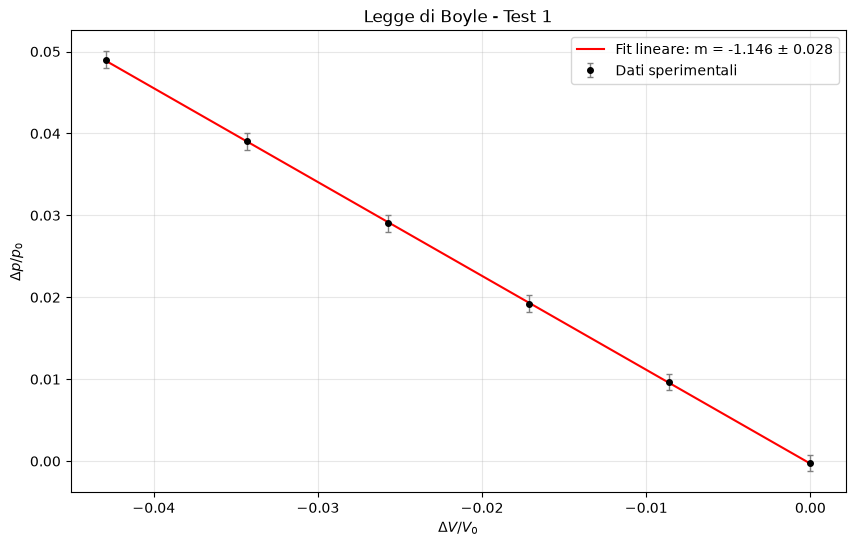


Test 2
  Stallo 1:    1.50–  18.10 s  P = 0.0192 kPa | sigma_A = 0.00006 kPa
  Stallo 2:   33.74–  60.32 s  P = 0.9804 kPa | sigma_A = 0.00026 kPa
  Stallo 3:   77.00–  95.74 s  P = 1.9583 kPa | sigma_A = 0.00027 kPa
  Stallo 4:  112.48– 127.14 s  P = 2.9623 kPa | sigma_A = 0.00036 kPa
  Stallo 5:  149.96– 169.74 s  P = 3.9889 kPa | sigma_A = 0.00025 kPa
  Stallo 6:  188.34– 207.52 s  P = 4.9881 kPa | sigma_A = 0.00026 kPa


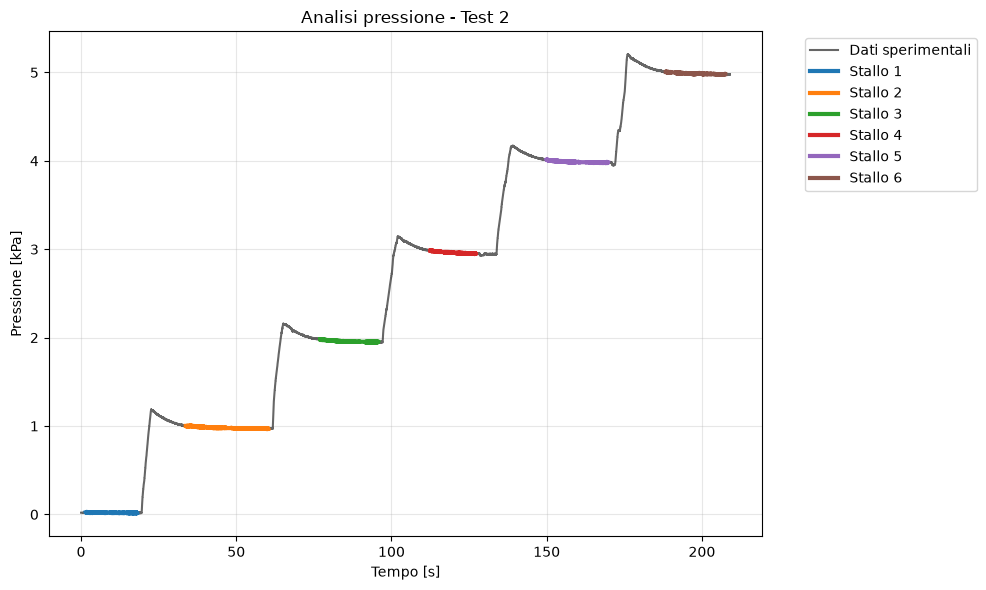


  delta p [kPa] | sigma [kPa] | delta V [ml]
     0.0192     | 0.10201     |    0.0
     0.9804     | 0.10201     |  -10.0
     1.9583     | 0.10201     |  -20.0
     2.9623     | 0.10201     |  -30.0
     3.9889     | 0.10201     |  -40.0
     4.9881     | 0.10201     |  -50.0

  m = -1.1497 ± 0.0281  (atteso -1)
  q = -0.00008 ± 0.00073
  chi2 / gdl = 0.21 / 4


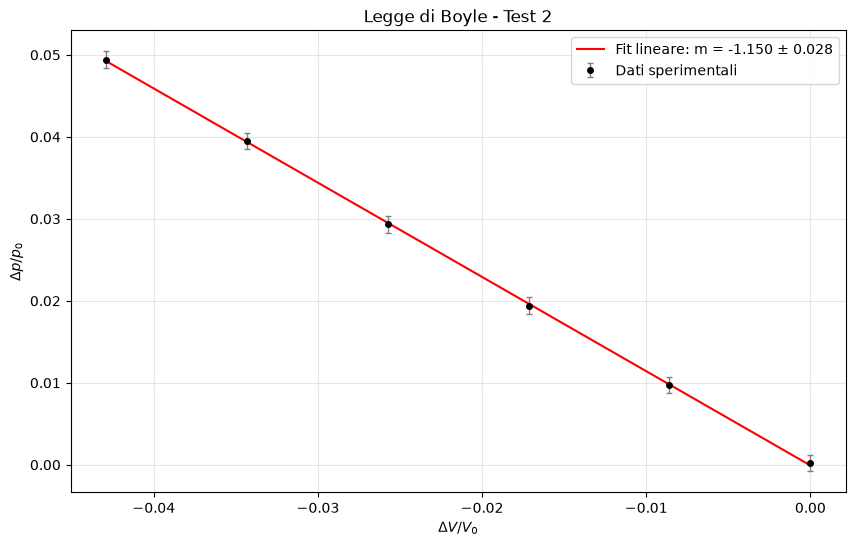


Test 3
  Stallo 1:    1.50–  18.22 s  P = -0.0101 kPa | sigma_A = 0.00011 kPa
  Stallo 2:   35.48–  64.18 s  P = 0.9996 kPa | sigma_A = 0.00022 kPa
  Stallo 3:   80.64– 112.50 s  P = 1.9724 kPa | sigma_A = 0.00028 kPa
  Stallo 4:  136.62– 151.24 s  P = 2.9679 kPa | sigma_A = 0.00017 kPa
  Stallo 5:  172.40– 195.66 s  P = 3.9891 kPa | sigma_A = 0.00017 kPa
  Stallo 6:  213.86– 250.64 s  P = 5.0067 kPa | sigma_A = 0.00027 kPa


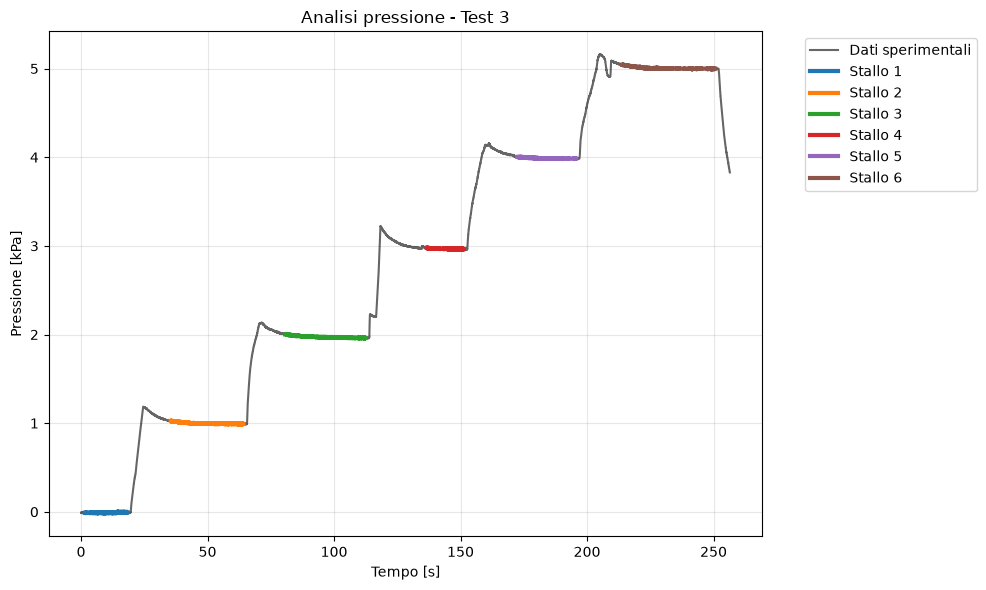


  delta p [kPa] | sigma [kPa] | delta V [ml]
    -0.0101     | 0.10201     |    0.0
     0.9996     | 0.10201     |  -10.0
     1.9724     | 0.10201     |  -20.0
     2.9679     | 0.10201     |  -30.0
     3.9891     | 0.10201     |  -40.0
     5.0067     | 0.10201     |  -50.0

  m = -1.1554 ± 0.0281  (atteso -1)
  q = -0.00016 ± 0.00073
  chi2 / gdl = 0.11 / 4


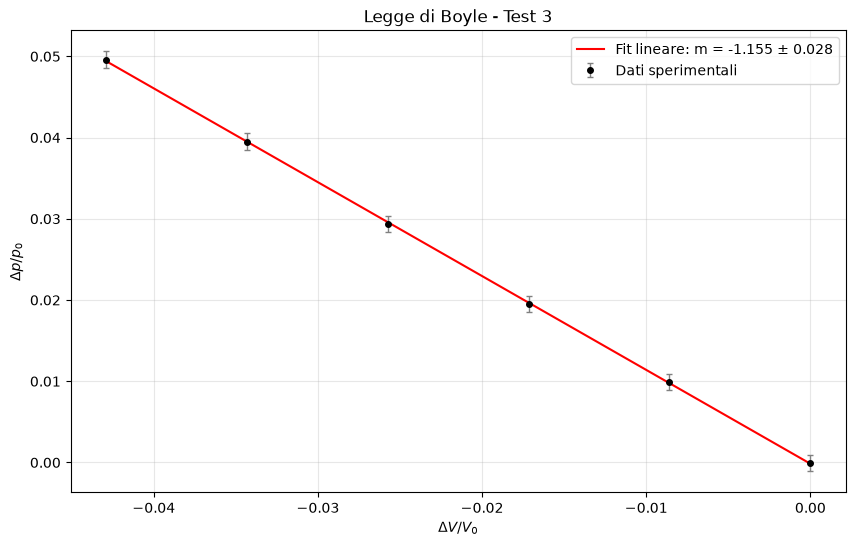


Test 4
  Stallo 1:    1.50–  25.42 s  P = -0.0273 kPa | sigma_A = 0.00008 kPa
  Stallo 2:   41.26–  67.86 s  P = 0.9345 kPa | sigma_A = 0.00024 kPa
  Stallo 3:   85.04– 107.12 s  P = 1.9187 kPa | sigma_A = 0.00025 kPa
  Stallo 4:  125.64– 144.88 s  P = 2.9330 kPa | sigma_A = 0.00028 kPa
  Stallo 5:  166.70– 203.44 s  P = 3.9589 kPa | sigma_A = 0.00031 kPa
  Stallo 6:  220.58– 238.54 s  P = 4.9693 kPa | sigma_A = 0.00036 kPa


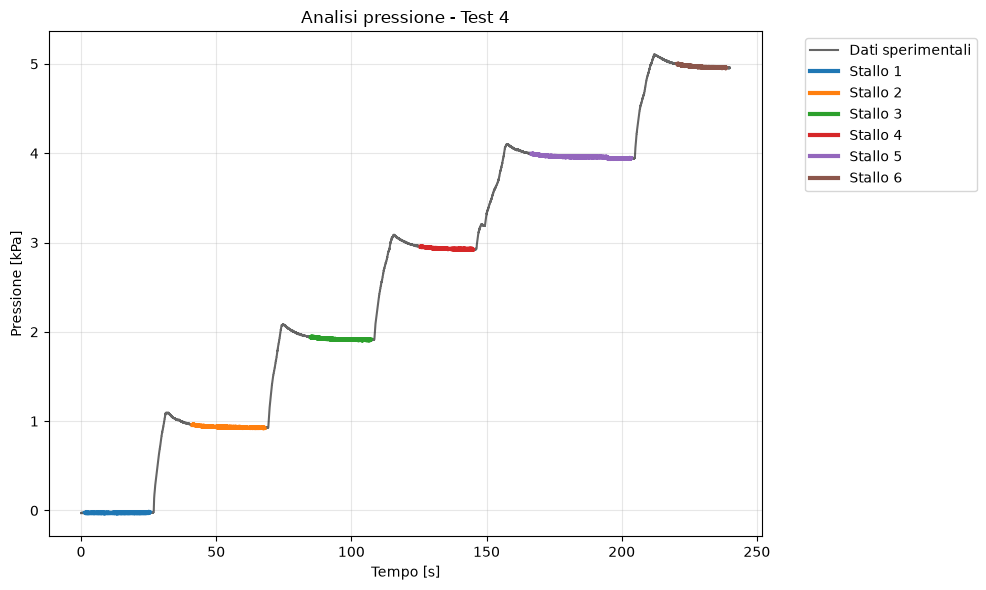


  delta p [kPa] | sigma [kPa] | delta V [ml]
    -0.0273     | 0.10201     |    0.0
     0.9345     | 0.10201     |  -10.0
     1.9187     | 0.10201     |  -20.0
     2.9330     | 0.10201     |  -30.0
     3.9589     | 0.10201     |  -40.0
     4.9693     | 0.10201     |  -50.0

  m = -1.1561 ± 0.0281  (atteso -1)
  q = -0.00057 ± 0.00073
  chi2 / gdl = 0.23 / 4


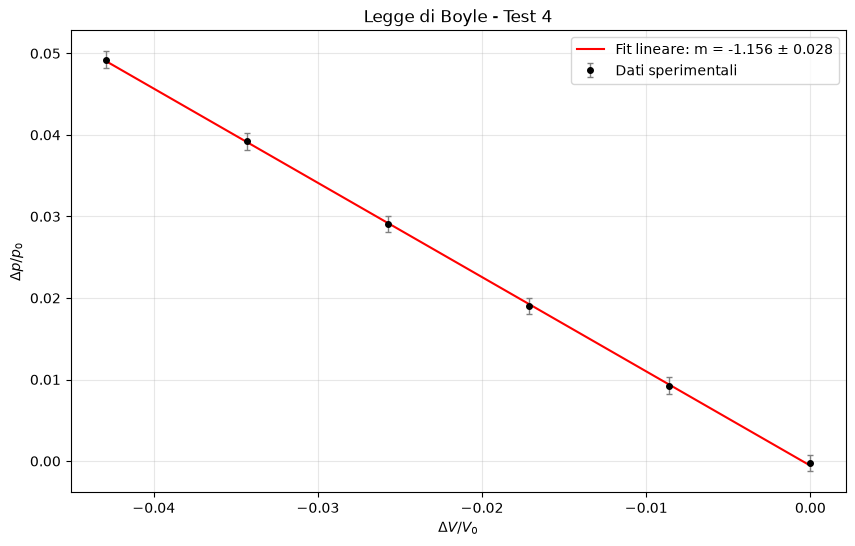

In [15]:
for i in range(1, 5):

    file = f"8/data/8-{i}"
    t, P = np.loadtxt(f"{file}.txt", unpack=True, skiprows=2, encoding='latin1',
                      converters={0: comma_to_float, 1: comma_to_float})

    zone = trova_stalli(t, P)
    n_stalli = len(zone)

    pressioni = np.zeros(n_stalli)
    sigma_a_p = np.zeros(n_stalli)

    plt.figure(figsize=(10, 6))
    plt.plot(t, P, color='black', alpha=0.6, label='Dati sperimentali')

    print(f"\nTest {i}")
    for j, (s, e) in enumerate(zone):
        seg = P[s:e]
        pressioni[j] = seg.mean()
        # INCERTEZZA DI TIPO A: deviazione standard della media sullo stallo
        sigma_a_p[j] = seg.std(ddof=1) / np.sqrt(len(seg))

        plt.plot(t[s:e], seg, linewidth=3, label=f'Stallo {j + 1}')
        print(f"  Stallo {j + 1}: {t[s]:7.2f}–{t[e-1]:7.2f} s  "
              f"P = {pressioni[j]:.4f} kPa | sigma_A = {sigma_a_p[j]:.5f} kPa")

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title(f"Analisi pressione - Test {i}")
    plt.xlabel("Tempo [s]")
    plt.ylabel("Pressione [kPa]")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{file}_analisi_transitorio.png", dpi=300)
    plt.show()

    # INCERTEZZA TOTALE (A + B): B = risoluzione/sqrt(12) e accuracy (da info)
    sigma_p = np.sqrt(sigma_a_p**2 + info.sigma_b_pressione_CI6534**2)

    # CALCOLO DEI DELTA p E DELTA V
    # Il CI-6534 misura gia' la pressione relativa all'ambiente -> P = delta p
    delta_p = pressioni
    delta_V = -np.arange(n_stalli) * V_diff   # compressioni: V - V0 < 0

    print("\n  delta p [kPa] | sigma [kPa] | delta V [ml]")
    for dp, sp, dv in zip(delta_p, sigma_p, delta_V):
        print(f"  {dp:9.4f}     | {sp:.5f}     | {dv:6.1f}")

    # Eq. 4: delta p / p0 = -(delta V / V0)
    x = delta_V / V_0
    y = delta_p / p_0
    sigma_y = sigma_p / p_0

    coefficienti, matrice_cov = np.polyfit(x, y, 1, w=1/sigma_y, cov='unscaled')
    a, b = coefficienti
    err_a, err_b = np.sqrt(np.diag(matrice_cov))

    chi2 = np.sum(((y - (a * x + b)) / sigma_y)**2)
    gdl = len(x) - 2

    print(f"\n  m = {a:.4f} ± {err_a:.4f}  (atteso -1)")
    print(f"  q = {b:.5f} ± {err_b:.5f}")
    print(f"  chi2 / gdl = {chi2:.2f} / {gdl}")

    m.append(a); sigma_m.append(err_a)
    q.append(b); sigma_q.append(err_b)

    x_fit = np.linspace(x.min(), x.max(), 100)

    plt.figure(figsize=(10, 6))
    plt.errorbar(x, y, yerr=sigma_y, fmt='o', color='black', markersize=4,
                 ecolor='gray', elinewidth=1, capsize=2, label="Dati sperimentali")
    plt.plot(x_fit, a * x_fit + b, color='red',
             label=f"Fit lineare: m = {a:.3f} ± {err_a:.3f}")
    plt.title(f"Legge di Boyle - Test {i}")
    plt.xlabel(r"$\Delta V / V_0$")
    plt.ylabel(r"$\Delta p / p_0$")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.savefig(f"{file}_fit_lineare.png", dpi=300)
    plt.show()

### Confronto tra le ripetizioni
Il punto 9 della scheda chiede di ripetere l'esperimento e confrontare i risultati, per valutare le incertezze sistematiche. Le liste diventano array numpy e si stampano $m_i \pm \sigma_{m_i}$ e $q_i \pm \sigma_{q_i}$ di ogni prova.


In [16]:
# CONFRONTO TRA LE RIPETIZIONI
m, sigma_m = np.array(m), np.array(sigma_m)
q, sigma_q = np.array(q), np.array(sigma_q)

for i in range(len(m)):
    print(f"m_{i} = {m[i]} +- {sigma_m[i]}")
    print(f"q_{i} = {q[i]} +- {sigma_q[i]}")

m_0 = -1.1458822920270104 +- 0.028135876183333127
q_0 = -0.00031146432946075025 +- 0.0007312047387523766
m_1 = -1.1496529088504746 +- 0.028135790562825194
q_1 = -8.045687311393597e-05 +- 0.000731204283676168
m_2 = -1.155383146293129 +- 0.028135786358471675
q_2 = -0.0001565460954697508 +- 0.0007312042401260785
m_3 = -1.1561439175490456 +- 0.028135826679401958
q_3 = -0.0005664355937752229 +- 0.0007312043376499838


### Pendenza media e incertezza sistematica da $V_0$
#### Media pesata
Le pendenze delle 4 prove si combinano con la media pesata sugli inversi delle varianze:
$$\bar m = \frac{\sum_i m_i/\sigma_{m_i}^2}{\sum_i 1/\sigma_{m_i}^2}, \qquad \sigma_{\bar m} = \frac{1}{\sqrt{\sum_i 1/\sigma_{m_i}^2}}.$$
Si stampa anche la **deviazione standard tra le prove**, che misura direttamente quanto è riproducibile l'esperimento. Se è molto più piccola delle $\sigma_{m_i}$, le incertezze dei singoli fit sono dominate da un contributo che non fluttua da una prova all'altra (l'accuracy).

> **Nota.** La media pesata tratta le $\sigma_{m_i}$ come indipendenti e quindi le riduce di circa $1/\sqrt{4}$. Però la parte dovuta all'accuracy viene dallo stesso sensore in tutte le prove ed è quindi comune. Se si vuole che l'accuracy non si riduca mediando, l'incertezza di $\bar m$ va presa pari a quella di una singola prova, più il sistematico da $V_0$.

#### Sistematico da $V_0$
Siccome $x = \Delta V/V_0$, la pendenza ricavata è proporzionale a $V_0$: un errore su $V_0$ scala tutte le $x$ di tutte le prove nello stesso modo. È quindi un errore **sistematico comune**, che non si riduce mediando e si somma dopo la media:
$$\sigma_{m,V_0} = |\bar m|\,\frac{\sigma_{V_b}}{V_0}, \qquad \sigma_{\bar m,\text{tot}} = \sqrt{\sigma_{\bar m}^2 + \sigma_{m,V_0}^2}.$$


In [17]:
pesi = 1 / sigma_m**2
m_medio = np.sum(pesi * m) / np.sum(pesi)
sigma_m_medio = 1 / np.sqrt(np.sum(pesi))
print(f"\nm medio pesato = {m_medio:.4f} ± {sigma_m_medio:.4f}")
print(f"dispersione tra le prove (std) = {m.std(ddof=1):.4f}")

# INCERTEZZA SISTEMATICA DA V0: x = delta V / V0 -> m e' proporzionale a V0, comune a tutte le prove
sigma_m_V0 = abs(m_medio) * sigma_V_b / V_0
sigma_m_tot = np.sqrt(sigma_m_medio**2 + sigma_m_V0**2)
print(f"m medio = {m_medio:.4f} ± {sigma_m_medio:.4f} (stat) ± {sigma_m_V0:.4f} (V0) -> ± {sigma_m_tot:.4f}")


m medio pesato = -1.1518 ± 0.0141
dispersione tra le prove (std) = 0.0049
m medio = -1.1518 ± 0.0141 (stat) ± 0.0049 (V0) -> ± 0.0149


### Grafico di confronto $m$–$q$
Ogni ripetizione è un punto nel piano $(m, q)$ con le sue barre d'errore. La linea tratteggiata indica il valore atteso $m = -1$.
- Se i punti sono raggruppati tra loro ma lontani da $-1$, l'esperimento è riproducibile e lo scostamento è un **errore di guadagno del sensore**, proprio quello che si vuole calibrare.
- Le intercette tutte compatibili con zero confermano che il sensore non ha un offset rilevabile a $\Delta V = 0$.


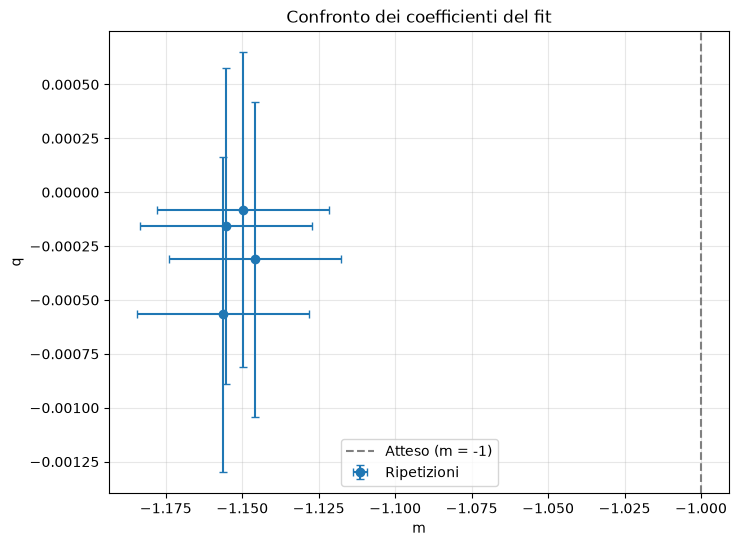

In [18]:
plt.figure(figsize=(8, 6))
plt.errorbar(m, q, xerr=sigma_m, yerr=sigma_q, fmt='o', capsize=3,
             label="Ripetizioni")
plt.axvline(-1, color='gray', linestyle='--', label="Atteso (m = -1)")
plt.title("Confronto dei coefficienti del fit")
plt.xlabel("m")
plt.ylabel("q")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Interpretazione e uso del risultato
La pendenza media $\bar m$ è il **coefficiente di calibrazione** del sensore di pressione (punto 8 della scheda).
- Se $|\bar m| > 1$, a parità di compressione il sensore legge un $\Delta p$ maggiore di quello previsto da Boyle.
- Nelle esperienze successive le pressioni lette con questo sensore si correggono dividendo per $|\bar m|$:
$$\Delta p_\text{vero} = \frac{\Delta p_\text{letto}}{|\bar m|}.$$

L'incertezza sul coefficiente si propaga di conseguenza.

Possibili cause di scostamento da $-1$ da discutere nella relazione:
- **Volumi morti non contati** (tubi, raccordi, camera del sensore): aumenterebbero il vero $V_0$, quindi farebbero crescere $|\bar m|$ e non lo spiegano se è già maggiore di 1.
- **Perdite di gas** durante gli stalli: abbasserebbero $\Delta p$, quindi ridurrebbero $|\bar m|$.
- **Temperatura non ancora di equilibrio** dopo ogni compressione: il gas compresso si scalda e $\Delta p$ verrebbe sovrastimato. È per questo che si aspettano alcuni secondi prima di ogni stallo.
- **Approssimazione al primo ordine** dell'eq. (4), valida per $|\Delta V| \ll V_0$ (qui fino a circa il 4%).
